# Naive Bayes
#### Zaire Robinson


Classifies the data while assuming each feature is idependent.


## Loading data

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB, GaussianNB, CategoricalNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("../data/supermarket_subset.csv")
df.head()


,transaction_id,transaction_line_id,basket_id,customer_id,store_id,product_id,employee_id,supplier_id,customer_age,customer_gender,...,units_sold,sales_revenue,profit_per_unit,profit_margin,sales_rank,category_sales_rank,product_popularity,product_growth_rate,product_return_rate,product_stockout_rate
0,T00021905,TL00021905,B00037526,C00035108,S00000063,P00001069,E00000401,SUP00000036,44,Female,...,7,15.68,-0.49,-0.219,125,47,0.1,-0.131,0.0720,0.0351
1,T00093977,TL00093977,B00028427,C00062754,S00000076,P00004268,E00000491,SUP00000006,43,Male,...,7,21.77,0.57,0.183,910,21,4.9,-0.063,0.0214,0.0594
2,T00074823,TL00074823,B00049794,C00024688,S00000040,P00000513,E00000418,SUP00000047,46,Female,...,16,96.96,3.03,0.500,754,11,4.5,0.396,0.0479,0.0823
3,T00063004,TL00063004,B00039714,C00093668,S00000032,P00004501,E00000230,SUP00000048,43,Female,...,5,27.85,-1.49,-0.268,495,10,6.1,0.218,0.0000,0.0763
4,T00054231,TL00054231,B00046502,C00038252,S00000021,P00001089,E00000478,SUP00000023,62,Other,...,9,149.31,9.23,0.556,441,44,3.0,-0.272,0.0358,0.0710


## Preparing Features

In [45]:
features = [
   
    'customer_visit_frequency',
    'customer_tenure_months',
    'days_since_last_purchase',
    'average_transaction_value',
    'loyalty_program_member',
    'product_category',
    'selling_price',
    'discount_percent',
    'promotion_active',
    'shopping_period'
]

target = 'repeat_purchase'

X = pd.get_dummies(df[features], drop_first=True)
y = df[target]

x_train, x_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=40, stratify=y) #splitting data for training. test size holds 30%. stratify=y ensures the class distribution is preserved.

x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, random_state=40, stratify=y_temp) #splitting data for validation and testing. test size is 50% of the remaining 30% of the data, which is 15% of the total data. stratify=y_temp ensures the class distribution is preserved.

print("training:", len(x_train), "validation:", len(x_val), "test:", len(x_test))

print(x_train.isnull().sum()[x_train.isnull().sum() > 0])


training: 8400 validation: 1800 test: 1800
Series([], dtype: int64)


## Modeling Validation

In [46]:



best_a, accuracy = 0, 0
for a in [0.1, 0.2, 0.3, 0.4, 0.5]:
    val_model = MultinomialNB(alpha=a) #better for searching probabilites in nonnegative inputs
    val_model.fit(x_train,y_train)
    current_accuracy = val_model.score(x_val, y_val)
    if current_accuracy > accuracy:
        best_a, accuracy = a, current_accuracy
print("Best alpha:", best_a)
print("Best accuracy:", accuracy)

nb_model = MultinomialNB(alpha=best_a)
nb_model.fit(x_train, y_train)
probabilities = nb_model.predict_proba(x_val)
yes_index = list(nb_model.classes_).index("Yes")

thresholds = [0.40, 0.50, 0.60, 0.70, 0.80]
for threshold in thresholds:
    model_predictions = np.where(probabilities[:, yes_index] >= threshold, "Yes", "No")
    print(f"Threshold: {threshold}")
    print(confusion_matrix(y_val, model_predictions, labels=['No', 'Yes']))
    print()
    


Best alpha: 0.1
Best accuracy: 0.5894444444444444
Threshold: 0.4
[[   0  731]
 [   3 1066]]

Threshold: 0.5
[[ 81 650]
 [ 89 980]]

Threshold: 0.6
[[400 331]
 [555 514]]

Threshold: 0.7
[[ 689   42]
 [1000   69]]

Threshold: 0.8
[[ 728    3]
 [1064    5]]



# Running Test

In [47]:
threshold = 0.5
model = MultinomialNB(alpha=best_a)
model.fit(x_train,y_train)
probabilities = model.predict_proba(x_test)
yes_index = list(model.classes_).index("Yes")
modelPrediction = np.where(probabilities[:, yes_index] >= threshold, "Yes", "No")
modelPrediction
print(y_test.value_counts())
print(confusion_matrix(y_test, modelPrediction, labels=['No', 'Yes']))

repeat_purchase
Yes    1068
No      732
Name: count, dtype: int64
[[ 89 643]
 [100 968]]


## Evaluation of the Predictions

In [48]:
total_predictions = len(modelPrediction)
print("Total predictions: ", total_predictions)
print("Correct predictions: ", np.sum(modelPrediction == y_test))
print("Accuracy: ", accuracy_score(y_test, modelPrediction))
print(classification_report(y_test, modelPrediction))

Total predictions:  1800
Correct predictions:  1057
Accuracy:  0.5872222222222222
              precision    recall  f1-score   support

          No       0.47      0.12      0.19       732
         Yes       0.60      0.91      0.72      1068

    accuracy                           0.59      1800
   macro avg       0.54      0.51      0.46      1800
weighted avg       0.55      0.59      0.51      1800



# Visualization

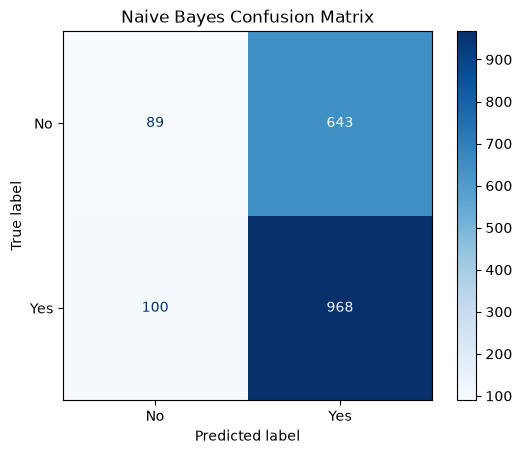

In [49]:
modelPrediction= model.predict(x_test)

cm = confusion_matrix(y_test, modelPrediction, labels=['No', 'Yes'])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No', 'Yes'])
display.plot(cmap = 'Blues', values_format='d')
plt.title("Naive Bayes Confusion Matrix")
plt.show()